My dataset has bright foci on the feeding channel on the FISH images. For this reason, I need to use the summed FISH channels as a fake segmentation marker. However, they have bright foci that make the trench row identification not work.

Here, I try to use the BF channel that I took to Filter out the feeding channels from the FISH channel

In [1]:
# import paulssonlab.deaton.trenchripper.trenchripper as tr
# import trenchripper as tr
import trenchripper as tr

import warnings
warnings.filterwarnings(action="once")

import matplotlib
matplotlib.rcParams["figure.figsize"] = [20, 10]

# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

import matplotlib.pyplot as plt
import numpy as np
import h5py
import skimage as sk

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


### Define parameters

These are the parameters used to find the feeding channels. They are essentially the same used normally when cropping kymographs

In [2]:
headpath = '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/Barcodes/hdf5/'
kymoclust = tr.kymograph_cluster(headpath=headpath,paramfile=False)

# Delete all attributes of kymoclust
for attr in list(kymoclust.__dict__.keys()):
    delattr(kymoclust, attr)

kymoclust.y_percentile = 95
kymoclust.y_foreground_percentile = 65
kymoclust.smoothing_kernel_y = (1, 51)
kymoclust.y_percentile_threshold = 0.7
kymoclust.y_min_edge_dist = 50
kymoclust.invert=False

In [3]:
dask_wd = "/home/lag36/scratch/lag36/dask"
dask_controller = tr.trcluster.dask_controller(
    walltime="2:00:00",
    local=False,
    n_workers=300,
    n_workers_min=20,
    memory="3GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

110m
2:00:00


### Define parameters

These are the parameters used to find the feeding channels. They are essentially the same used normally when cropping kymographs

In [3]:
FEEDING_CHANNEL_BUFFER_SIZE_PIXELS = 3
BUFFER_IMAGE_EDGE_PIXELS = 50

def get_smoothed_y_percentiles_from_array(img_arr,
                                          kymoclust,
                                          invert:bool,  
                                          y_percentile,
                                          y_foreground_percentile,
                                          smoothing_kernel_y):
    """For a given array, computes the percentile along the x-axis of
    the segmentation channel, generating a (y,t) array. Then performs
    median filtering of this array for smoothing.
    Args:
        img_arr (np.ndarray): 3D array of shape (y,x,t) containing the segmentation channel data.
        kymoclust (tr.kymograph_cluster): Kymograph cluster object containing parameters.
        invert (bool): If True, inverts the image array before processing.
        y_percentile (int): Percentile to compute along the x-axis.
        y_foreground_percentile (int): Percentile to use for foreground normalization.
        smoothing_kernel_y (tuple): Kernel size for median filtering along the y-axis.
    Returns:
        h5py.File: Hdf5 file handle corresponding to the output hdf5 dataset "data", a smoothed
        percentile array of shape (y,t).
    """
    if invert:
        img_arr = sk.util.invert(img_arr)
    perc_arr = np.percentile(img_arr,y_percentile,axis=2,interpolation='lower')
    y_percentiles_smoothed = kymoclust.median_filter_2d(perc_arr,smoothing_kernel_y)

    min_qth_percentile = y_percentiles_smoothed.min(axis=1)[:, np.newaxis]
##             max_qth_percentile = y_percentiles_smoothed.max(axis=1)[:, np.newaxis]
    max_qth_percentile = np.percentile(y_percentiles_smoothed,y_foreground_percentile,axis=1)[:, np.newaxis]
    y_percentiles_smoothed = (y_percentiles_smoothed - min_qth_percentile)/(max_qth_percentile - min_qth_percentile)
    y_percentiles_smoothed = np.minimum(y_percentiles_smoothed,1.)

    return y_percentiles_smoothed

def get_feeding_channel_edges(img_arr:np.ndarray):
    '''
    Find edges of the feeding channels in the image array. It expects BF images
    This function uses functions from tr.kymograph_cluster
    Parameters:
    - img_arr: numpy array of shape (t, y, x) containing the BF images
    '''
    smoothed_y_percentiles = get_smoothed_y_percentiles_from_array(img_arr=img_arr,
                                        kymoclust=kymoclust,
                                        invert=kymoclust.invert,
                                     y_percentile=kymoclust.y_percentile,
                                     y_foreground_percentile=kymoclust.y_foreground_percentile,
                                     smoothing_kernel_y=kymoclust.smoothing_kernel_y)
    
    # Trim edges to avoid unwanted peaks
    smoothed_y_percentiles[:,:BUFFER_IMAGE_EDGE_PIXELS] = 0
    smoothed_y_percentiles[:,-BUFFER_IMAGE_EDGE_PIXELS:] = 0

    trench_edges_y , _, _ = kymoclust.get_trench_edges_y(y_percentiles_smoothed_array = smoothed_y_percentiles,
                                    y_percentile_threshold=kymoclust.y_percentile_threshold,
                                    y_min_edge_dist=kymoclust.y_min_edge_dist)
    
    # Convert to numpy array and validate its shape
    # This will fail if shapes are not consistent (i.e. different number of peaks found at different timepoints)
    trench_edges_y = np.array(trench_edges_y)
    if trench_edges_y.shape[0] != 15 or trench_edges_y.shape[1] != 18:
        raise ValueError(f"Expected shape (18, 15) elements, but got shape ({trench_edges_y.shape}).")

    # Get the feeding channel edges
    feeding_channel_boundary_indices = [0,
                                        1, 4,
                                        5, 8,
                                        9, 12,
                                        13, 16,
                                        17]
    
    feeding_channel_edges = trench_edges_y[:, feeding_channel_boundary_indices]

    # mask_feeding_channels = np.zeros(img_arr.shape, dtype=bool)
    # for i in range(0, len(feeding_channel_edges), 2):
    #     mask_feeding_channels[feeding_channel_edges[i]:feeding_channel_edges[i+1], :] = True

    return feeding_channel_edges

def generate_feeding_channel_mask_per_timepoint(feeding_channel_edges_timepoint, buffer_size_pixels, shape):
    """
    Generate a mask for the feeding channels based on the edges provided.

    Parameters:
    - feeding_channel_edges_time: List of edges for the feeding channels at a specific timepoint.
    - shape: Shape of the mask to be generated.

    Returns:
    - mask: A boolean mask with True values in the feeding channel regions.
    """
    # mask_feeding_channels = np.zeros_like(BF[0], dtype=bool)
    # mask_feeding_channels[:feeding_channel_edges_time[0], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[1]:feeding_channel_edges_time[2], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[3]:feeding_channel_edges_time[4], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[5]:feeding_channel_edges_time[6], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[7]:feeding_channel_edges_time[8], :] = True
    # mask_feeding_channels[feeding_channel_edges_time[9]:, :] = True
    mask = np.zeros(shape, dtype=bool)
    for i in range(0, len(feeding_channel_edges_timepoint), 2):
        mask[feeding_channel_edges_timepoint[i]+buffer_size_pixels:feeding_channel_edges_timepoint[i+1]-buffer_size_pixels, :] = True
    return mask

def generate_feeding_channel_mask_all_timepoints(feeding_channel_edges, shape):
    mask_all_timepoints = np.zeros(shape, dtype=bool)
    for time_index in range(shape[0]):
        mask_feeding_channels = generate_feeding_channel_mask_per_timepoint(feeding_channel_edges[time_index], FEEDING_CHANNEL_BUFFER_SIZE_PIXELS, shape[1:])
        mask_all_timepoints[time_index] = mask_feeding_channels

    return mask_all_timepoints

def clean_feeding_channels(img_arr_to_clean, img_array_to_find_feeding_channels):
    feeding_channel_edges = get_feeding_channel_edges(img_array_to_find_feeding_channels)
    mask_all_timepoints = generate_feeding_channel_mask_all_timepoints(feeding_channel_edges, img_array_to_find_feeding_channels.shape)

    img_arr_masked = img_arr_to_clean * mask_all_timepoints
    return img_arr_masked

def create_fake_seg_channel(filepath, fish_channels = ["RFP", "Cy5"], seg_channel_name = 'seg'):
    """
    Create a synthetic segmentation channel based on the provided fish channels.
    The synthetic channel is generated by taking the 98th percentile projection of each fish channel,
    normalizing it, and then combining them into a single channel.
    The resulting synthetic channel is saved in the HDF5 file with the specified name.

    Parameters:
    - filepath (str): Path to the HDF5 file.
    - fish_channels (list): List of fish channel names to be used for generating the synthetic channel.
    - seg_channel_name (str): Name for the synthetic segmentation channel to be saved in the HDF5 file.
    """
    with h5py.File(filepath,"r+") as infile:

        n_timepoints = infile[fish_channels[0]].shape[0]
        img_dimensions = infile[fish_channels[0]].shape[1:]
        # dimesions (N_channels, Y, X)
        percentile_projections = np.zeros((len(fish_channels), *img_dimensions))
            
        for i, channel in enumerate(fish_channels):
            channel_arr = np.percentile(infile[channel][:],98,axis=0)
            channel_arr = channel_arr/channel_arr.max()
            percentile_projections[i] = channel_arr
        
        percentile_projection_all_channels = 10000*np.percentile(percentile_projections,98,axis=0)
        percentile_projection_all_channels_times = np.stack(
            [percentile_projection_all_channels for i in range(n_timepoints)],axis=0).astype("uint16")

        if seg_channel_name in infile.keys():
            del infile[seg_channel_name]
        infile[seg_channel_name] = percentile_projection_all_channels_times
    return 0

def clean_feeding_channels_hdf5(filepath,
                                channel_to_find_feeding_channels = 'BF',
                                channel_to_clean_feeding_channels = 'seg',
                                channel_name_cleaned_feeding_channels = 'seg_cleaned'):
    """
    Clean the feeding channels in an HDF5 file.

    Parameters:
    - filepath (str): Path to the HDF5 file.
    - channel_to_find_feeding_channels (str): Name of the channel used to identify feeding channels.
    - channel_to_rm_feeding_channels (str): Name of the channel from which to remove feeding channels.
    - channel_name_cleaned_feeding_channels (str): Name for the cleaned feeding channels to be saved in the HDF5 file.
    """
    
    with h5py.File(filepath,"r+") as infile:
        img_arr_to_clean = infile[channel_to_clean_feeding_channels]
        img_array_to_find_feeding_channels = infile[channel_to_find_feeding_channels]

        img_arr_masked = clean_feeding_channels(img_arr_to_clean, img_array_to_find_feeding_channels)

        if channel_name_cleaned_feeding_channels in infile.keys():
            del infile[channel_name_cleaned_feeding_channels]
        infile[channel_name_cleaned_feeding_channels] = img_arr_masked
    
    return 0

def rename_and_delete_channels_from_hdf5_files(
    filepath,
    seg_channel_initial_name = 'seg_cleaned',
    seg_channel_final_name = 'BF',
    channels_to_delete = ['seg', 'seg_cleaned']
):
    """
    Rename the segmentation channel in an HDF5 file and delete specified channels.
    Args:
        headpath (str): Path to the directory containing the HDF5 files.
        filename (str): Name of the HDF5 file to process.
        seg_channel_initial_name (str): Name of the initial segmentation channel to rename.
        seg_channel_final_name (str): New name for the segmentation channel.
        channels_to_delete (list): List of channel names to delete from the HDF5 file.
    Returns:
        int: Returns 0 upon successful completion.
    """
    with h5py.File(filepath,"r+") as infile:
        if seg_channel_final_name in infile.keys():
            del infile[seg_channel_final_name]
        infile[seg_channel_final_name]  = infile[seg_channel_initial_name]

        for seg_channel in channels_to_delete:
            if seg_channel in infile.keys():
                del infile[seg_channel]
    return 0

# Dask stuff
import pandas as pd
def parse_and_save_futures_results(futures_dict, function_name):
    """
    Parse the results of futures and save them to a DataFrame and a pickle file.
    Args:
        futures_dict (dict): Dictionary with filenames as keys and futures as values.
        function_name (str): Name of the function used to generate the futures.
    Returns:
        pd.DataFrame: DataFrame containing the status, done, result, and exception of each future.
    """
    def parse_futures_dict_entry_to_row(future):
        """
        Parse a single future entry to a dictionary row.
        Args:
            future (dask.distributed.Future): Future object to parse.
        Returns:
            dict: Dictionary containing the status, done, result, and exception of the future.
        """
        try:
            result = str(future.result())
        except Exception as e:
            result = str(e)
        future_dict_row = {'status': future.status,
                    'done':future.done(),
                    'result': result,
                    'exception': str(future.exception()),
                    'key': future.key}
        return future_dict_row

    futures_dict_to_table = {filename: parse_futures_dict_entry_to_row(future)
                          for filename, future in futures_dict.items()}
    
    df_futures = (pd.DataFrame
                  .from_dict(futures_dict_to_table, orient='index')
                  .astype({'status': 'category',
                           'done': bool,
                           'result': 'object',
                           'exception': 'object'})
                  .reset_index()
                  .rename(columns={'index': 'filename'})
                  .sort_values(by='filename', ascending=True))

    df_futures.to_pickle(f"{headpath}/futures_{function_name}.pkl")

    return df_futures

def deploy_function_in_dask(function, 
                            headpath,
                            filenames,
                            *args,
                            **kwargs):
    """
    Deploy a function in Dask for each filename in the list.
    Args:
        function (callable): Function to deploy.
        filenames (list): List of filenames to process.
        *args: Additional positional arguments for the function.
        **kwargs: Additional keyword arguments for the function.
    Returns:
        dict: Dictionary with filenames as keys and futures as values.
    """
    # futures = []
    futures_dict = {}
    for filename in filenames:
        future = dask_controller.daskclient.submit(function,
                                               headpath+filename, # Notice how it is formatted: filename is relative to headpath
                                               *args,
                                               **kwargs)
        # futures.append(future)
        futures_dict[filename] = future
    # results = dask_controller.daskclient.gather(futures)
    df_futures = parse_and_save_futures_results(futures_dict, function.__name__)
    return df_futures

## Execution

In [4]:
import glob
headpath = '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/Barcodes/hdf5/'
full_filepaths_hdf5 = glob.glob(headpath + '/*.hdf5')
filenames_hdf5 = [filename.split('/')[-1] for filename in full_filepaths_hdf5]

In [10]:
filename = full_filepaths_hdf5[100]
with h5py.File(filename, "r") as infile:
    print(infile.keys())
    img_arr = infile['Cy7'][:]
    print(infile['BF'].shape)

<KeysViewHDF5 ['BF', 'Cy5', 'Cy7', 'RFP']>
(10, 2960, 2960)


In [11]:
smoothed_y_percentiles = get_smoothed_y_percentiles_from_array(img_arr=img_arr,
                                     kymoclust=kymoclust,
                                     invert=kymoclust.invert,
                                     y_percentile=kymoclust.y_percentile,
                                     y_foreground_percentile=kymoclust.y_foreground_percentile,
                                     smoothing_kernel_y=kymoclust.smoothing_kernel_y)

/tmp/ipykernel_1201542/1380048350.py:26: DeprecationWarning: the `interpolation=` argument to percentile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  perc_arr = np.percentile(img_arr,y_percentile,axis=2,interpolation='lower')


In [12]:
smoothed_y_percentiles[:,:BUFFER_IMAGE_EDGE_PIXELS] = 0
smoothed_y_percentiles[:,-BUFFER_IMAGE_EDGE_PIXELS:] = 0

In [13]:
trench_edges_y , _, _ = kymoclust.get_trench_edges_y(y_percentiles_smoothed_array = smoothed_y_percentiles,
                                    y_percentile_threshold=kymoclust.y_percentile_threshold,
                                    y_min_edge_dist=kymoclust.y_min_edge_dist)

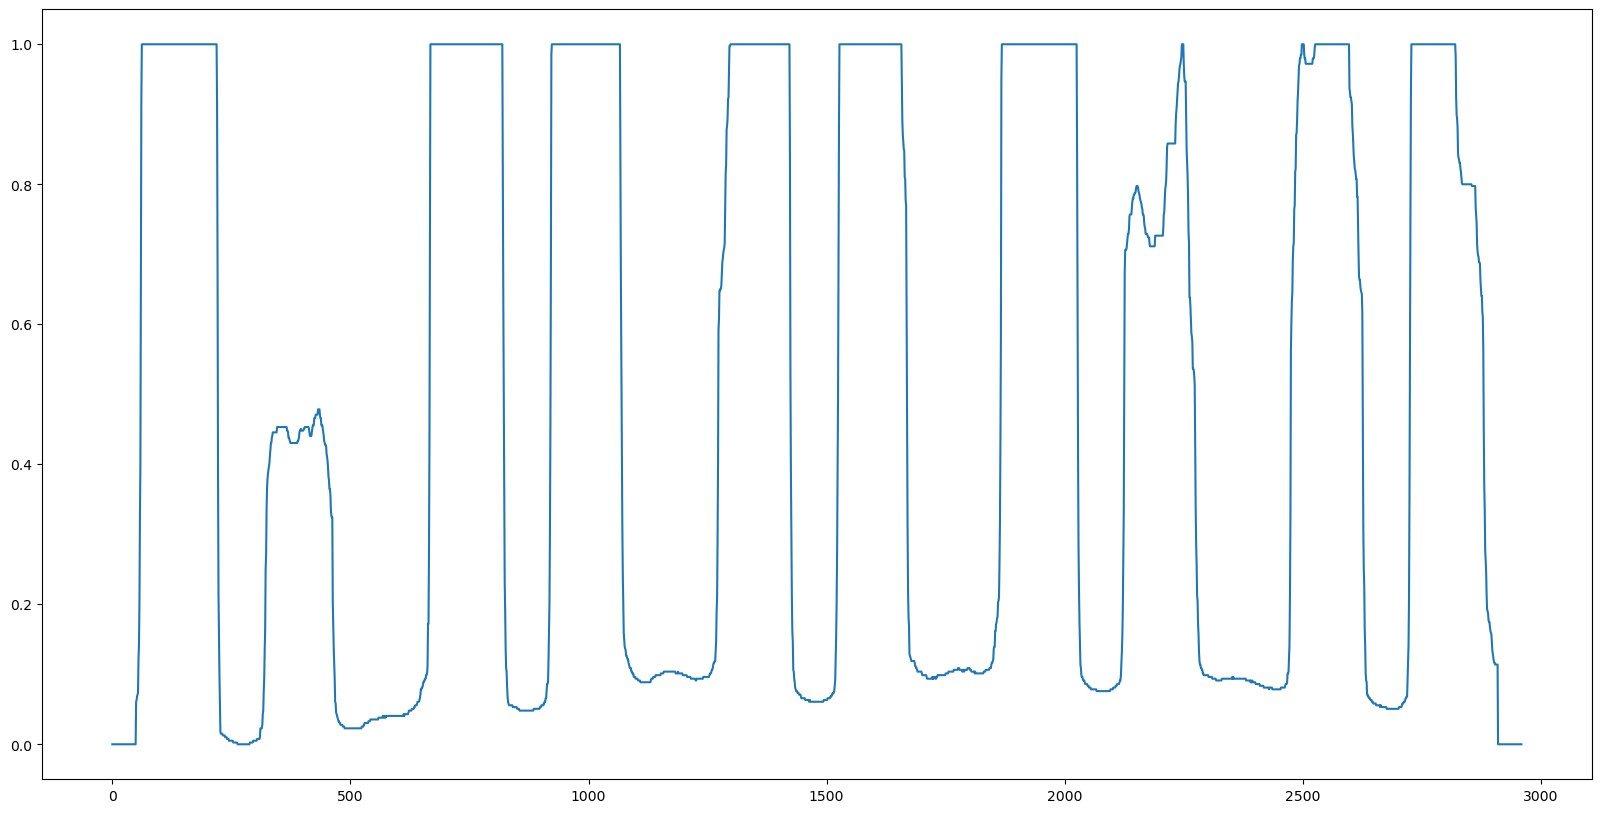

In [14]:
plt.plot(smoothed_y_percentiles[3])

In [56]:
len(trench_edges_y)

10

In [57]:
[len(trench_edges_y[i]) for i in range(len(trench_edges_y))]

[20, 20, 20, 20, 20, 20, 20, 20, 20, 20]

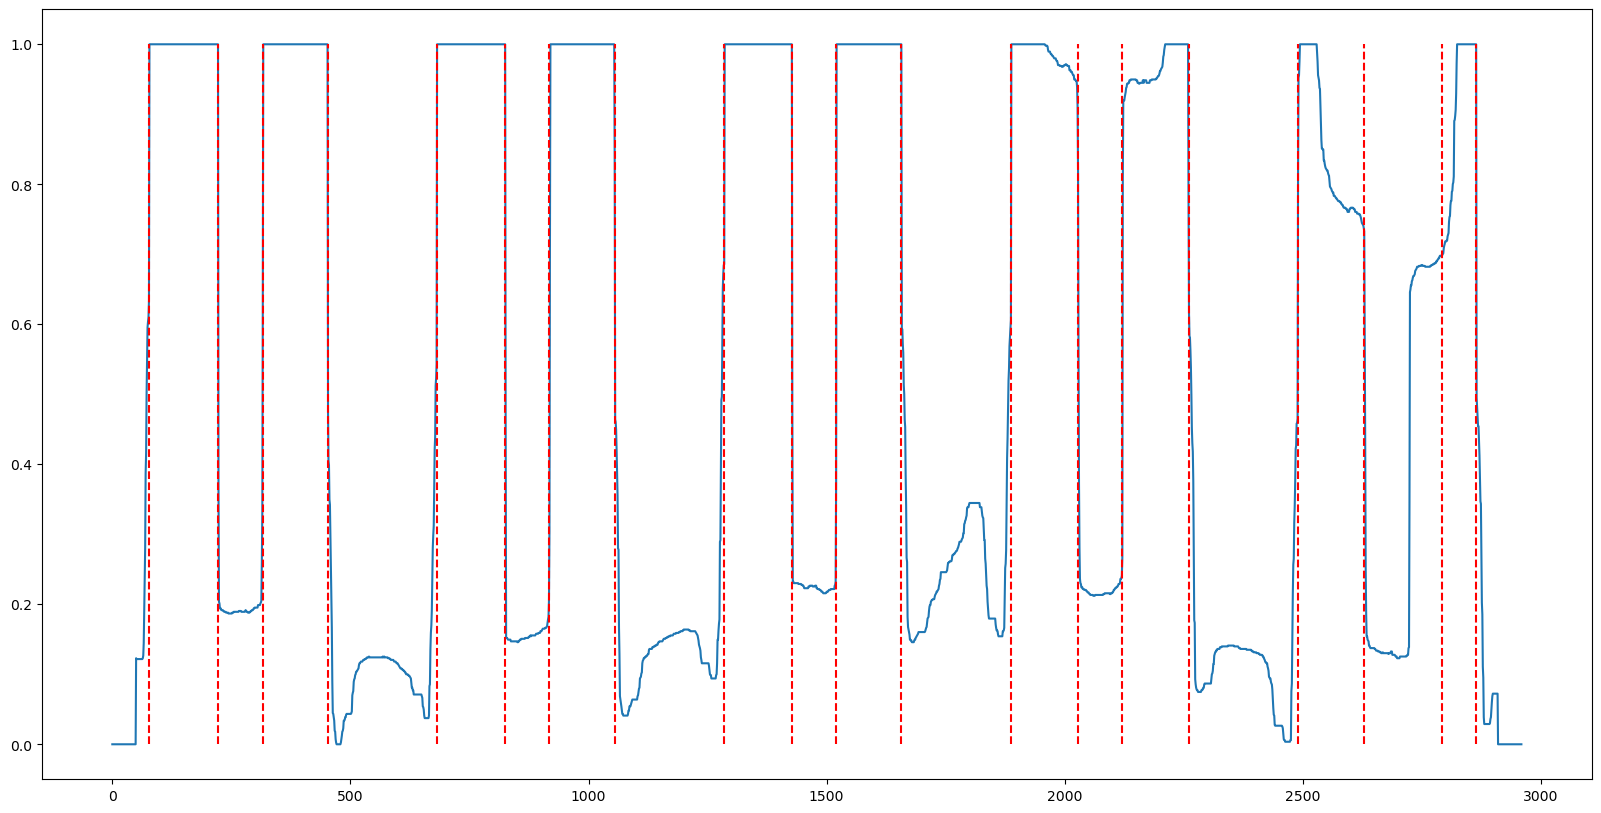

In [64]:
t = 3
plt.plot(smoothed_y_percentiles[3])
plt.vlines(trench_edges_y[t], 0, 1, color='red', linestyle='--')

In [26]:
get_feeding_channel_edges(img_arr)

/tmp/ipykernel_1888381/1380048350.py:26: DeprecationWarning: the `interpolation=` argument to percentile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  perc_arr = np.percentile(img_arr,y_percentile,axis=2,interpolation='lower')


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (10,) + inhomogeneous part.

#### Create fake seg channel

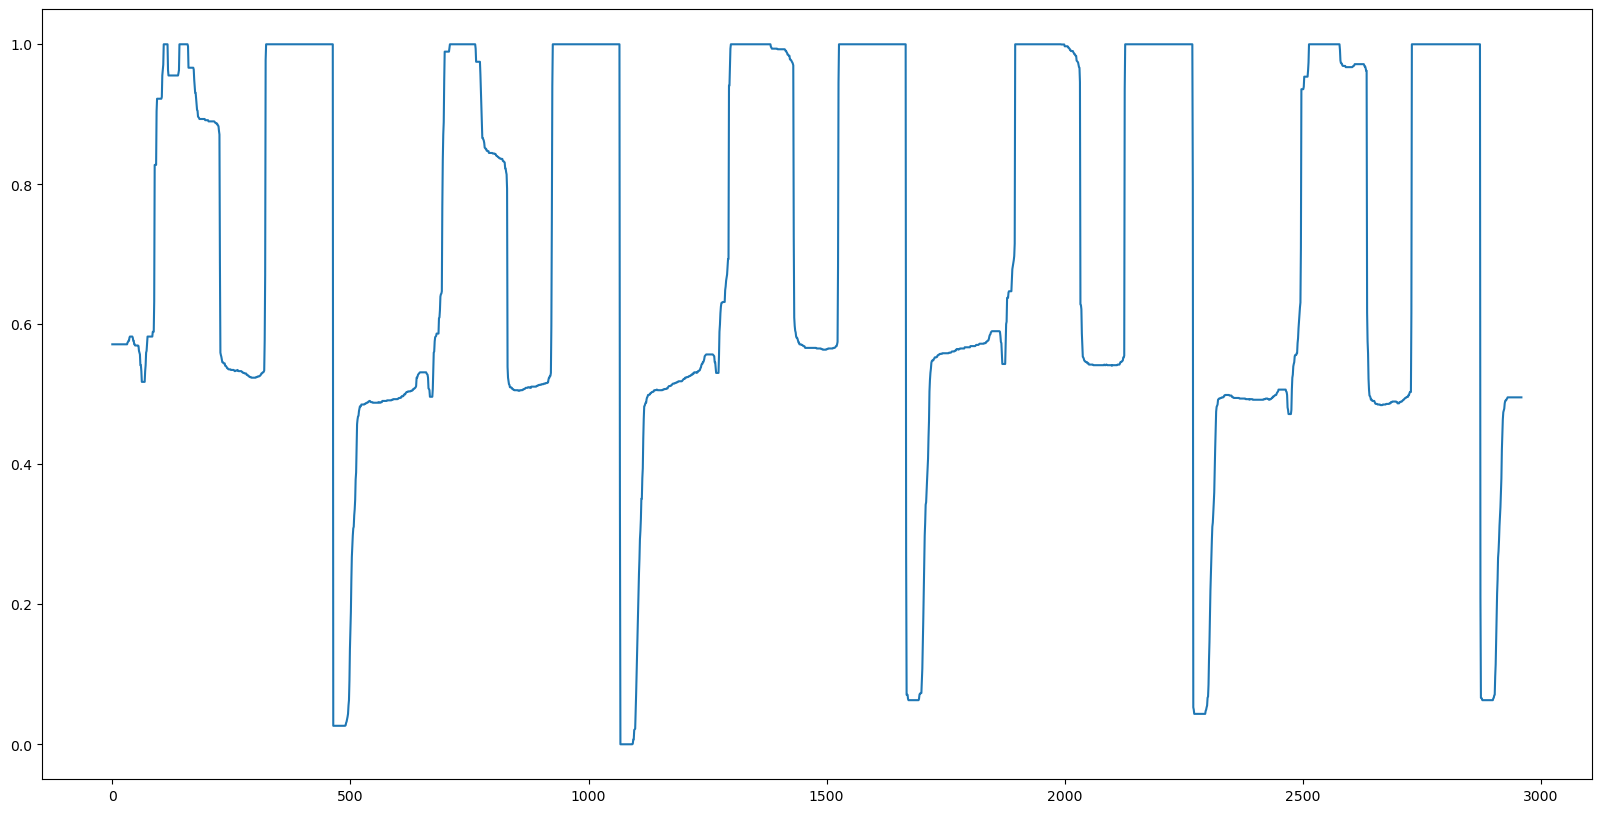

In [25]:
plt.plot(y_percentiles_smoothed[3])  

In [8]:
df_futures = deploy_function_in_dask(
    create_fake_seg_channel,
    headpath,
    filenames_hdf5,
    fish_channels=["RFP", "Cy5"],
    seg_channel_name='seg'
)

#### Clean feeding channels

In [10]:
df_futures = deploy_function_in_dask(
    clean_feeding_channels_hdf5,
    headpath,
    filenames_hdf5,
    channel_to_find_feeding_channels='BF',
    channel_to_clean_feeding_channels='seg',
    channel_name_cleaned_feeding_channels='seg_cleaned'
)

#### Fix erred futures

In [23]:
# Debug single erred future
df_futures[df_futures['result']!='0'].iloc[0]

filename                                         hdf5_312.hdf5
status                                                   error
done                                                      True
result       setting an array element with a sequence. The ...
exception    setting an array element with a sequence. The ...
key          clean_feeding_channels_hdf5-3d4d62b40241992707...
Name: 238, dtype: object

In [32]:
# Create a new channel with the cleaned segmentation data just as a copy of the seg channel (it will fail, but just for consisteny)
filepath = headpath + 'hdf5_312.hdf5'
seg_channel_cleaned_name = 'seg_cleaned'
seg_channel_name = 'seg'
with h5py.File(filepath,"r+") as infile:
    keys = infile.keys()
    print(keys)
    infile[seg_channel_cleaned_name] = infile[seg_channel_name]

<KeysViewHDF5 ['BF', 'Cy5', 'RFP', 'seg']>


In [33]:
with h5py.File(filepath,"r") as infile:
    keys = infile.keys()
    print(keys)

<KeysViewHDF5 ['BF', 'Cy5', 'RFP', 'seg', 'seg_cleaned']>


#### Rename and delete channels from hdf5 files

In [37]:
df_futures = deploy_function_in_dask(
    rename_and_delete_channels_from_hdf5_files,
    headpath,
    filenames_hdf5,
    seg_channel_initial_name = 'seg_cleaned',
    seg_channel_final_name = 'BF',
    channels_to_delete = ['seg', 'seg_cleaned']
)

In [45]:
dask_controller.shutdown()

Done.


2025-05-27 11:44:15,667 - distributed.deploy.adaptive_core - INFO - Adaptive stop


## Test single file

<KeysViewHDF5 ['BF', 'Cy5', 'RFP']>


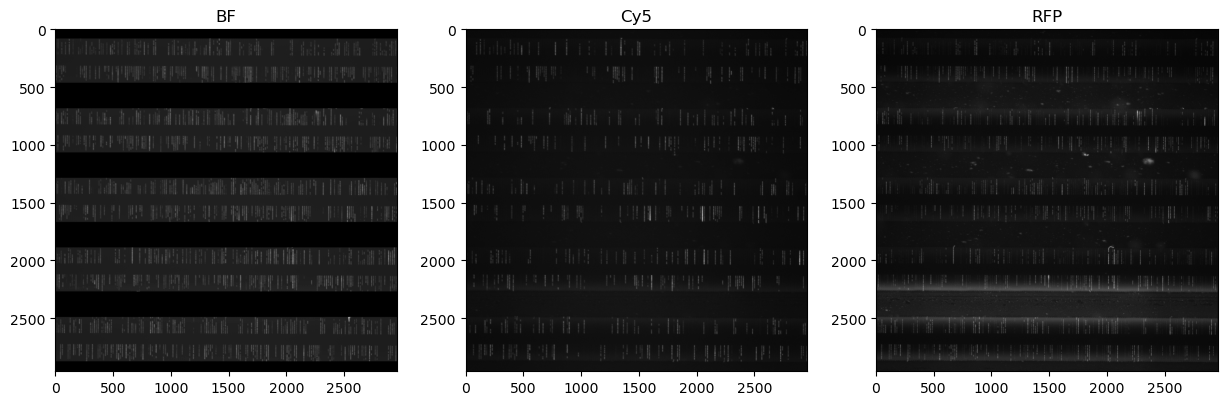

In [57]:
# # Load file
# with h5py.File(headpath+"/hdf5_0.hdf5","r") as imported_hdf5_handle:
#     img_bf_test_0 = imported_hdf5_handle['BF'][:] #t x y

# with h5py.File(headpath+"/hdf5_50.hdf5","r") as imported_hdf5_handle:
#     img_bf_test_50 = imported_hdf5_handle['BF'][:] #t x y

# with h5py.File(headpath+"/hdf5_594.hdf5","r") as imported_hdf5_handle:
#     img_bf_test_594 = imported_hdf5_handle['BF'][:] #t x y

# # Run function
filepath = headpath + '/hdf5_511.hdf5'
# clean_feeding_channels_hdf5(filepath=filepath,
#                             channel_to_find_feeding_channels = 'BF',
#                             channel_to_clean_feeding_channels = 'seg',
#                             channel_name_cleaned_feeding_channels = 'seg_cleaned')
# Plot results
with h5py.File(filepath,"r") as infile:
    keys = infile.keys()
    print(keys)
    fig, ax = plt.subplots(1, len(keys), figsize=(5*len(keys), 5))
    for i, key in enumerate(keys):
        ax[i].imshow(infile[key][14], cmap='gray')
        ax[i].set_title(key)